# Las desintegraciones del $\tau$

### Análisis de datos simulados

D. Costas y J. A. Hernando

*Departamento de Física de Partículas. Universidade de Santiago de Compostela*

*Versión 2026/27, revisada (la original es de noviembre de 2022)*

## Objetivos

* Identificar los **canales de desintegración** del $\tau$ a partir de las partículas detectadas, y medir sus
  fracciones.

* Distinguir por la forma de su **espectro de energía** una desintegración a dos cuerpos ($\tau \to \pi + \nu_\tau$)
  de una a tres ($\tau \to e + \bar\nu_e + \nu_\tau$).

* Reconstruir el **vértice de desintegración** con las trayectorias, y medir la **vida media** del $\tau$.

* Reconstruir el **neutrino**, que no se detecta, con la conservación del cuadrimomento.

La teoría está en [leptones](../leptones.ipynb), sección 1 (desintegraciones y universalidad), y en
[introducción](../introduccion.ipynb), sección 3 (vida media, masa invariante).

## Los datos

El fichero `taus_45GeV.csv` (en el aula virtual) contiene 30 000 sucesos. En cada uno se produce **un** $\tau^-$ o $\tau^+$ en el
origen, siempre con la misma energía (cerca de 45 GeV: la medirás en el Taller 3), en una dirección al azar.

El detector es **ideal**: una esfera de 5 cm de radio centrada en el origen, sin campo magnético, que mide sin
error la posición en la que la atraviesa cada $\gamma$, $e^\pm$, $\mu^\pm$ y $\pi^\pm$, su momento y su energía. Los
neutrinos no se detectan.

Cada fila es una partícula. Columnas: `event` (número de suceso), `particleName` (`gamma`, `e-`, `e+`, `mu-`,
`mu+`, `pi-`, `pi+`), `x`, `y`, `z` (punto de la esfera, en mm), `px`, `py`, `pz` y `E` (en MeV).

Como no hay campo magnético, las trayectorias son **rectas**: cada partícula viene del vértice de desintegración
del $\tau$ en la dirección de su momento.

El trabajo se puede hacer individualmente o en grupos de hasta cuatro personas, y se entrega en la tarea
correspondiente del aula virtual.

In [1]:
# Configuración e imports
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Los datos no están en GitHub: descarga taus_45GeV.csv del aula virtual y guárdalo en datos/,
# junto a este cuaderno (o cambia DATOS por la ruta donde lo tengas)
DATOS = 'datos/'

def lee(nombre):
    try:
        return pd.read_csv(DATOS + nombre)
    except FileNotFoundError:
        raise FileNotFoundError('No encuentro {}{}: descárgalo del aula virtual y ponlo en {}'.format(DATOS, nombre, DATOS))

# Colores Okabe-Ito (legibles con daltonismo), y además estilos de línea distintos
AZUL, NARANJA, BERMELLON, VERDE, CELESTE = '#0072B2', '#E69F00', '#D55E00', '#009E73', '#56B4E9'

# Constantes (PDG)
M_TAU, TAU_TAU, C = 1776.86, 2.903e-13, 2.998e11      # MeV, s, mm/s
M_PI, M_PI0       = 139.57, 134.98                    # MeV

data = lee('taus_45GeV.csv')
data.head()

,event,particleName,x,y,z,px,py,pz,E
0,0,gamma,-46.665398,14.573922,10.485294,-4108.790087,1283.199766,923.202142,4402.392510
1,0,gamma,-46.554595,14.452292,11.126588,-21958.518406,6816.712327,5248.202276,23583.632558
2,0,pi-,-46.000031,16.477644,10.605868,-9160.779055,3281.545421,2112.151205,9958.367124
3,1,mu+,-13.628892,-3.544433,-47.975935,-5514.644806,-1398.599609,-19290.163449,20111.910844
4,2,gamma,47.077349,-14.529804,8.521030,1265.384717,-389.821084,228.823194,1343.696027


## Herramientas

Funciones para trabajar con los sucesos. Puedes usar otras.

In [2]:
def canal(nombres):
    # Canal detectado: '2 gamma, 1 pi-' = dos fotones y un pi-. Nombres ordenados: el texto es siempre el mismo
    nombres = list(nombres)
    return ', '.join('{} {}'.format(nombres.count(n), n) for n in sorted(set(nombres)))

def carga(nombres):
    # Carga total del suceso, en unidades de e
    return sum(('+' in n) - ('-' in n) for n in nombres)

def particulas(data, ievento):
    # Posiciones (mm), momentos (MeV), energías (MeV) y nombres de las partículas de un suceso
    d = data[data.event == ievento]
    return d[['x', 'y', 'z']].to_numpy(), d[['px', 'py', 'pz']].to_numpy(), d.E.to_numpy(), list(d.particleName)

def masa_invariante(E, p):
    # E: energías, p: momentos (una fila por partícula)
    Et, pt = np.sum(E), np.sum(p, axis=0)
    return np.sqrt(max(Et**2 - pt @ pt, 0))

def interseccion(x1, v1, x2, v2):
    # Punto de la recta x1 + t1 v1 más cercano a la recta x2 + t2 v2 (el corte, si se cortan)
    A = np.stack([v1, -v2], axis=1)
    t = np.linalg.lstsq(A, x2 - x1, rcond=None)[0]
    return x1 + t[0] * v1

# Una tabla con un suceso por fila: canal, carga, energía visible
sucesos = data.groupby('event').agg(canal=('particleName', canal), carga=('particleName', carga),
                                    Evis=('E', 'sum'), n=('E', 'size'))
sucesos.head()

,canal,carga,Evis,n
event,,,,
0,"2 gamma, 1 pi-",-1,37944.392192,3
1,1 mu+,1,20111.910844,1
2,"2 gamma, 1 pi-",-1,29631.183238,3
3,"4 gamma, 1 pi-",-1,45276.245579,5
4,"2 gamma, 1 pi-",-1,46632.598961,3


In [3]:
# Ejemplo: el suceso 0
x, p, E, nombres = particulas(data, 0)
print('canal:', sucesos.canal[0], '| carga:', sucesos.carga[0])
fot = [i for i, n in enumerate(nombres) if n == 'gamma']
print('masa invariante de los dos fotones = {:.2f} MeV'.format(masa_invariante(E[fot], p[fot])))
v = interseccion(x[fot[0]], p[fot[0]], x[fot[1]], p[fot[1]])
print('vértice de los dos fotones (mm) =', v.round(4), '| distancia al origen = {:.3f} mm'.format(np.linalg.norm(v)))

canal: 2 gamma, 1 pi- | carga: -1
masa invariante de los dos fotones = 134.98 MeV
vértice de los dos fotones (mm) = [-0.0192  0.006   0.0044] | distancia al origen = 0.021 mm


## 1. ¿Cuántos $\tau^-$ y cuántos $\tau^+$?

<div class="admonition tip">
<p class="admonition-title"><b>[>] Taller — Contar por la carga</b></p>

1. Con la carga total de cada suceso, cuenta los $\tau^-$ y los $\tau^+$.
2. ¿Es compatible la diferencia con que se produzcan los mismos de cada uno?
3. Hay sucesos con un par $e + e^+$ además de otras partículas. ¿Estropean la cuenta?

</div>

In [4]:
print(sucesos.carga.value_counts())
n_menos, n_mas = (sucesos.carga == -1).sum(), (sucesos.carga == 1).sum()
print('diferencia = {}, sigma = sqrt(N) = {:.0f}'.format(n_mas - n_menos, np.sqrt(len(sucesos))))

carga
 1    15103
-1    14897
Name: count, dtype: int64
diferencia = 206, sigma = sqrt(N) = 173


<details>
<summary><b>Solución</b></summary>

1. 14 897 $\tau^-$ y 15 103 $\tau^+$; todos los sucesos tienen carga $\pm1$.
2. Si cada suceso es $\tau^-$ o $\tau^+$ con probabilidad $\frac12$, la diferencia $N_+ - N_-$ tiene una desviación
   estándar $\sqrt N = 173$. La medida, 206, está a $1.2\sigma$: compatible.
3. No: el par $e + e^+$ de un fotón convertido tiene carga cero.

</details>

## 2. Los canales de desintegración

<div class="admonition tip">
<p class="admonition-title"><b>[>] Taller — Del detector a la física</b></p>

1. Haz la lista de canales detectados y sus fracciones. Junta $\tau^-$ y $\tau^+$.
2. Asocia cada canal detectado con una desintegración del $\tau$, con las páginas del $\tau$, del $\pi^0$ y del
   $\pi^\pm$ del [PDG](https://pdg.lbl.gov). ¿De dónde salen los fotones? ¿Y los pares $e + e^+$?
3. Compara las fracciones con las del PDG. Los canales simulados no son todos los del $\tau$: ¿qué fracción del
   total suman? Renormaliza y compara de nuevo.
4. Hay tres sucesos raros (`1 mu-, 1 pi+, 1 pi-`, `2 gamma, 1 mu-`...). ¿Qué les ha pasado?

</div>

particleName
2 gamma, 1 pi         0.2754
1 e                   0.2037
1 mu                  0.1897
1 pi                  0.1222
3 pi                  0.1037
4 gamma, 1 pi         0.1000
2 e, 1 gamma, 1 pi    0.0032
2 e, 3 gamma, 1 pi    0.0019
4 e, 2 gamma, 1 pi    0.0000
1 mu, 2 pi            0.0000
2 gamma, 1 mu         0.0000


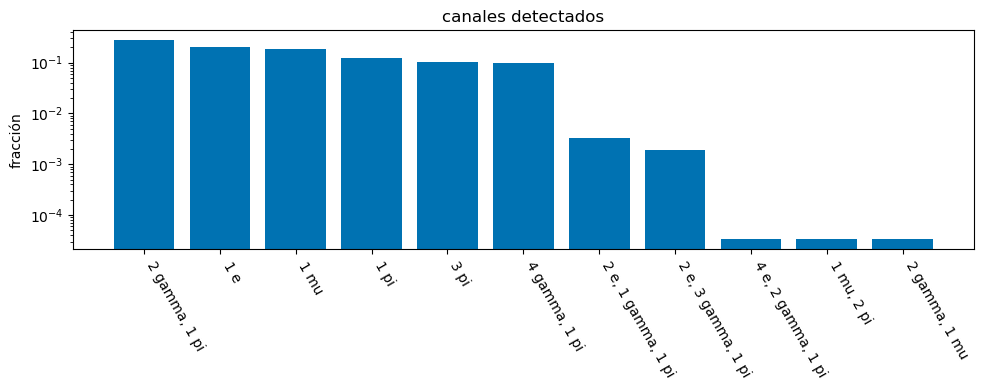

In [5]:
# El canal sin el signo de la carga: 'pi-' y 'pi+' cuentan igual
canal_sin_carga = data.particleName.str.rstrip('+-').groupby(data.event).agg(canal)
fr = canal_sin_carga.value_counts() / len(sucesos)
print(fr.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(fr)), fr.values, color=AZUL)
ax.set_xticks(range(len(fr))); ax.set_xticklabels(fr.index, rotation=-60, ha='left')
ax.set_yscale('log'); ax.set_ylabel('fracción'); ax.set_title('canales detectados')
plt.tight_layout(); plt.show()

In [6]:
# Agrupamos en desintegraciones del tau (un fotón convertido da e + e+ y un fotón menos)
def desintegracion(c):
    n = {k: 0 for k in ('gamma', 'e', 'mu', 'pi')}
    for trozo in c.split(', '):
        num, nombre = trozo.split(' ')
        n[nombre.rstrip('+-')] += int(num)
    conv = (n['e'] - 1) // 2 + 1 if n['e'] > 1 else 0     # pares e+e de conversiones
    if n['pi'] == 0 and n['mu'] == 0 and n['e'] == 1: return 'e nu nu'
    if n['pi'] == 0 and n['mu'] == 1 and n['gamma'] == 0: return 'mu nu nu'
    if n['pi'] == 3: return '3 pi nu'
    if n['pi'] == 1:
        ngam = n['gamma'] + conv
        return {0: 'pi nu', 2: 'pi pi0 nu', 4: 'pi 2pi0 nu'}.get(ngam, 'otros')
    return 'otros'

sucesos['desint'] = sucesos.canal.map(desintegracion)
pdg = pd.Series({'e nu nu': 17.82, 'mu nu nu': 17.39, 'pi nu': 10.82, 'pi pi0 nu': 25.49,
                 'pi 2pi0 nu': 9.26, '3 pi nu': 8.99})
tabla = pd.DataFrame({'muestra (%)': 100 * sucesos.desint.value_counts() / len(sucesos), 'PDG (%)': pdg})
tabla['PDG renormalizado (%)'] = 100 * pdg / pdg.sum()
tabla['error muestra (%)'] = 100 * np.sqrt(tabla['muestra (%)']/100 * (1 - tabla['muestra (%)']/100) / len(sucesos))
print('suma de los canales simulados en el PDG: {:.1f} %'.format(pdg.sum()))
tabla.round(2)

suma de los canales simulados en el PDG: 89.8 %


,muestra (%),PDG (%),PDG renormalizado (%),error muestra (%)
3 pi nu,10.37,8.99,10.01,0.18
e nu nu,20.37,17.82,19.85,0.23
mu nu nu,18.97,17.39,19.37,0.23
otros,0.01,NaN,NaN,0.00
pi 2pi0 nu,10.20,9.26,10.32,0.17
pi nu,12.22,10.82,12.05,0.19
pi pi0 nu,27.87,25.49,28.39,0.26


<details>
<summary><b>Solución</b></summary>

1. Doce canales con fracción apreciable: $e$, $\mu$, $\pi$, $\pi + 2\gamma$, $\pi + 4\gamma$ y $3\pi$ (cada uno con las
   dos cargas), más un 0.5 % con pares $e + e^+$ y unos pocos sucesos raros.
2. | detectado | desintegración ($\tau^-$) |
   |:--|:--|
   | $e$ | $\tau \to e + \bar\nu_e + \nu_\tau$ |
   | $\mu$ | $\tau \to \mu + \bar\nu_\mu + \nu_\tau$ |
   | $\pi^-$ | $\tau \to \pi^- + \nu_\tau$ |
   | $\pi^- + 2\gamma$ | $\tau \to \pi^- + \pi^0 + \nu_\tau$, con $\pi^0 \to \gamma + \gamma$ ($98.8\,\%$, $c\tau = 25$ nm) |
   | $\pi^- + 4\gamma$ | $\tau \to \pi^- + 2\pi^0 + \nu_\tau$ |
   | $\pi^- + \pi^+ + \pi^-$ | $\tau \to \pi^- + \pi^+ + \pi^- + \nu_\tau$ |

   Los fotones son del $\pi^0$, que se desintegra en el mismo punto que el $\tau$. Los pares $e + e^+$ son
   conversiones $\gamma \to e + e^+$ en el material (o la desintegración Dalitz del $\pi^0$, $1.2\,\%$).
3. Los seis canales simulados suman el 89.8 % de las desintegraciones del $\tau$: faltan los kaones, el
   $3\pi + \pi^0$, $\pi + 3\pi^0$, etc. Las fracciones de la muestra son **relativas** a estos seis. Renormalizadas, las
   del PDG se parecen a las de la muestra, pero no del todo: el error de cada fracción es
   $\sqrt{f(1-f)/N} \simeq 0.2\,\%$, y las diferencias llegan a $2$–$2.5\sigma$ ($e$: $20.4$ frente a $19.9\,\%$). Seguramente la
   muestra se generó con otras fracciones (las de otra edición del PDG, o redondeadas).
4. Un $\pi^\pm$ que se ha desintegrado, $\pi \to \mu + \bar\nu_\mu$, dentro de la esfera. Con $p \sim 10$ GeV, el
   pión vuela de media $\gamma\beta c\tau_\pi \simeq 70 \times 7.8\ \mathrm{m} \simeq 560$ m: la probabilidad de que se desintegre en
   5 cm es $\sim 10^{-4}$, y entre unos 12 000 piones salen uno o dos.

</details>

## 3. Las energías: dos cuerpos frente a tres

<div class="admonition tip">
<p class="admonition-title"><b>[>] Taller — La forma del espectro</b></p>

1. Dibuja la distribución de la energía del $e$ y del $\mu$ en los sucesos con un solo leptón, y la del $\pi$ en los
   sucesos con un solo $\pi$.
2. ¿En qué se parecen las del $e$ y el $\mu$? ¿Por qué? (Recuerda la universalidad leptónica.)
3. ¿Por qué la del $\pi$ es plana? *Pista:* en el reposo del $\tau$, ¿cuánto vale la energía del $\pi$ en
   $\tau \to \pi + \nu_\tau$? ¿Y la del $e$ en $\tau \to e + \bar\nu_e + \nu_\tau$?
4. ¿Cuánto vale la energía máxima del $\pi$ en el laboratorio? Usa el extremo del espectro para medir la
   **energía de los $\tau$** de la muestra. ¿Es 45 GeV?

</div>

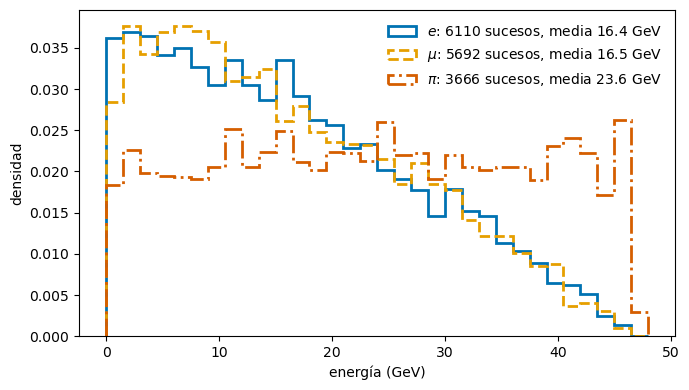

energía media: e 16.4 GeV, mu 16.5 GeV, pi 23.6 GeV
energía máxima del pi: 46651 MeV;  mayor energía visible de toda la muestra: 46670 MeV


In [7]:
uno = lambda nombre: sucesos.canal.isin(['1 ' + nombre + '-', '1 ' + nombre + '+'])
E_e, E_mu, E_pi = sucesos.Evis[uno('e')], sucesos.Evis[uno('mu')], sucesos.Evis[uno('pi')]

bins = np.linspace(0, 48000, 33)
fig, ax = plt.subplots(figsize=(7, 4))
for E, col, ls, nom in [(E_e, AZUL, '-', r'$e$'), (E_mu, NARANJA, '--', r'$\mu$'), (E_pi, BERMELLON, '-.', r'$\pi$')]:
    ax.hist(E/1000, bins/1000, histtype='step', lw=2, color=col, ls=ls, density=True,
            label='{}: {} sucesos, media {:.1f} GeV'.format(nom, len(E), E.mean()/1000))
ax.set_xlabel('energía (GeV)'); ax.set_ylabel('densidad'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print('energía media: e {:.1f} GeV, mu {:.1f} GeV, pi {:.1f} GeV'.format(E_e.mean()/1e3, E_mu.mean()/1e3, E_pi.mean()/1e3))
print('energía máxima del pi: {:.0f} MeV;  mayor energía visible de toda la muestra: {:.0f} MeV'.format(
      E_pi.max(), sucesos.Evis.max()))

<details>
<summary><b>Solución</b></summary>

1. y 2. Las del $e$ y el $\mu$ son casi iguales (medias de 16.4 y 16.5 GeV): la misma interacción, la misma
   fracción, $17.8$ y $17.4\,\%$ (universalidad), y $m_\mu \ll m_\tau$, así que la masa apenas cuenta. Es un espectro a tres
   cuerpos: los dos neutrinos se llevan la mayor parte de la energía, y la media es $\simeq 0.35\,E_\tau$.
3. A dos cuerpos, en el reposo del $\tau$ la energía del $\pi$ es **fija**,
   $E^* = (m_\tau^2 + m_\pi^2)/2m_\tau = 894$ MeV, y su dirección es isótropa. En el laboratorio,
   $E = \gamma(E^* + \beta p^*\cos\theta^*)$: una distribución uniforme en $\cos\theta^*$ da una distribución
   **uniforme en $E$**, entre $\gamma(E^* - \beta p^*)$ y $\gamma(E^* + \beta p^*)$. (Si los $\tau$ estuvieran
   polarizados, como en LEP, la recta tendría pendiente.) En el de tres cuerpos, la energía del $e$ en el reposo
   del $\tau$ ya es una distribución, y la del laboratorio se acumula a energías bajas.
4. Como $E^* + p^* = m_\tau$ (el $\nu$ no tiene masa), $E_{\max} = \gamma(E^* + \beta p^*) \simeq \gamma m_\tau = E_\tau$. El
   espectro del $\pi$ acaba en **46.65 GeV**, y la mayor energía visible de la muestra es 46.67 GeV: **los $\tau$ de la
   muestra tienen $E_\tau \simeq 46.67$ GeV**, no 45 GeV. (El nombre del fichero no es exacto; lo confirma el
   Taller 5.) El mínimo, $\gamma(E^* - \beta p^*) \simeq E_\tau\,m_\pi^2/m_\tau^2 = 0.29$ GeV.

</details>

## 4. El vértice y la vida media

<div class="admonition tip">
<p class="admonition-title"><b>[>] Taller — ¿Cuánto vuela un $	au$?</b></p>

1. Comprueba que la masa invariante de los dos fotones de los sucesos $\pi + 2\gamma$ es la del $\pi^0$. En los de
   $\pi + 4\gamma$, ¿cómo se emparejan los fotones?
2. El vértice de desintegración del $\tau$ es el punto donde se cortan dos trayectorias cualesquiera de sus
   productos. ¿Por qué sirven los dos fotones, si vienen del $\pi^0$? ¿Por qué no se puede en los canales con una
   sola partícula?
3. Calcula la distancia de vuelo en los canales $\pi + 2\gamma$, $\pi + 4\gamma$ y $3\pi$. Dibuja su distribución en
   escala logarítmica. ¿Qué forma tiene?
4. Calcula la distancia media que se espera con $E_\tau = 45$ GeV y con la energía del Taller 3, y compárala con
   la medida.
5. Mide la **vida media** del $\tau$ con su error. Compárala con la del PDG, $\tau_\tau = 290.3$ fs.

</div>

In [8]:
# 1. Masa de los dos fotones
m2g = []
for ev in sucesos.index[sucesos.canal.isin(['2 gamma, 1 pi-', '2 gamma, 1 pi+'])][:2000]:
    x, p, E, nombres = particulas(data, ev)
    f = [i for i, n in enumerate(nombres) if n == 'gamma']
    m2g.append(masa_invariante(E[f], p[f]))
print('m(2 gamma) = {:.2f} ± {:.2f} MeV en {} sucesos'.format(np.mean(m2g), np.std(m2g), len(m2g)))

m(2 gamma) = 134.98 ± 0.00 MeV en 2000 sucesos


pi pi0  :  8263 sucesos, distancia media 2.293 ± 0.025 mm
pi 2pi0 :  3000 sucesos, distancia media 2.316 ± 0.043 mm
3 pi    :  3111 sucesos, distancia media 2.252 ± 0.041 mm


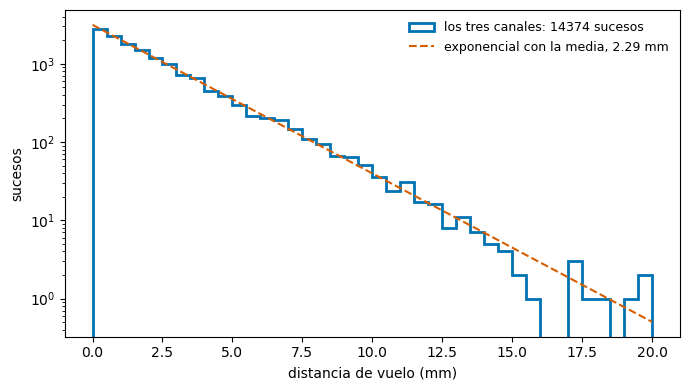

In [9]:
# 3. Distancia de vuelo: el corte de las dos primeras trayectorias del suceso
canales_vertice = {'pi pi0': ['2 gamma, 1 pi-', '2 gamma, 1 pi+'],
                   'pi 2pi0': ['4 gamma, 1 pi-', '4 gamma, 1 pi+'],
                   '3 pi': ['1 pi+, 2 pi-', '2 pi+, 1 pi-']}
vertices = {}
for nombre, lista in canales_vertice.items():
    evs = set(sucesos.index[sucesos.canal.isin(lista)])
    d = data[data.event.isin(evs)]
    vs = []
    for ev, s in d.groupby('event'):
        x, p = s[['x', 'y', 'z']].to_numpy(), s[['px', 'py', 'pz']].to_numpy()
        vs.append(interseccion(x[0], p[0], x[1], p[1]))
    vertices[nombre] = np.array(vs)

L = {k: np.linalg.norm(v, axis=1) for k, v in vertices.items()}
todas = np.concatenate(list(L.values()))

for k, l in L.items():
    print('{:8s}: {:5d} sucesos, distancia media {:.3f} ± {:.3f} mm'.format(k, len(l), l.mean(), l.std() / np.sqrt(len(l))))

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 20, 41)
ax.hist(todas, bins, histtype='step', lw=2, color=AZUL, label='los tres canales: {} sucesos'.format(len(todas)))
xx = np.linspace(0, 20, 100)
ax.plot(xx, len(todas) * (bins[1] - bins[0]) / todas.mean() * np.exp(-xx / todas.mean()), color=BERMELLON, ls='--',
        label='exponencial con la media, {:.2f} mm'.format(todas.mean()))
ax.set_yscale('log'); ax.set_xlabel('distancia de vuelo (mm)'); ax.set_ylabel('sucesos'); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
# 4. y 5. Distancia esperada y vida media
def gamma_beta(E):
    return np.sqrt(E**2 - M_TAU**2) / M_TAU

E_TAU = 46670.   # MeV, del Taller 3
d_med, d_err = todas.mean(), todas.std() / np.sqrt(len(todas))
for E in (45000., E_TAU):
    print('E_tau = {:.2f} GeV: gamma beta = {:.2f}, <d> esperada = {:.3f} mm, tau medida = {:.1f} ± {:.1f} fs'.format(
          E/1000, gamma_beta(E), gamma_beta(E) * C * TAU_TAU, d_med / (gamma_beta(E) * C) * 1e15,
          d_err / (gamma_beta(E) * C) * 1e15))
print('<d> medida = {:.3f} ± {:.3f} mm ({} sucesos)'.format(d_med, d_err, len(todas)))

E_tau = 45.00 GeV: gamma beta = 25.31, <d> esperada = 2.202 mm, tau medida = 301.7 ± 2.5 fs
E_tau = 46.67 GeV: gamma beta = 26.25, <d> esperada = 2.284 mm, tau medida = 290.9 ± 2.4 fs
<d> medida = 2.289 ± 0.019 mm (14374 sucesos)


<details>
<summary><b>Solución</b></summary>

1. $m_{\gamma\gamma} = 134.98$ MeV en todos los sucesos, la masa del $\pi^0$ (el detector es ideal: no hay
   resolución). En $\pi + 4\gamma$ hay tres emparejamientos; el bueno es el que da dos veces $m_{\pi^0}$. Para el
   vértice no hace falta emparejar.
2. El $\pi^0$ vive $8.5 \times 10^{-17}$ s ($c\tau = 25$ nm): se desintegra prácticamente donde se desintegra el $\tau$, y sus
   fotones salen de ese punto. Con una sola trayectoria no hay corte; la trayectoria no pasa por el origen,
   pero solo da una cota (el parámetro de impacto).
3. Una **exponencial**, como la ley de desintegración (una recta en escala logarítmica). Los tres canales dan la misma
   media dentro de los errores: 2.29, 2.32 y 2.25 mm.
4. Con $E_\tau = 45$ GeV, $\gamma\beta = 25.31$ y $\langle d \rangle = \gamma\beta c\tau_\tau = 2.203$ mm; con 46.67 GeV,
   $\gamma\beta = 26.25$ y $2.284$ mm. Se miden $2.289 \pm 0.019$ mm (14 374 sucesos): a $4.6\sigma$ de lo esperado con
   45 GeV, y compatible con 46.67 GeV.
5. $\tau_\tau = \langle d \rangle / (\gamma\beta c)$: $291 \pm 2$ fs con $E_\tau = 46.67$ GeV, compatible con el PDG. Con 45 GeV saldría
   $302 \pm 3$ fs, un 4 % alto: **para medir una vida media hay que conocer el momento**. (La media es el estimador
   de máxima verosimilitud de una exponencial, y su error, $\langle d \rangle/\sqrt N$.)

</details>

## 5. El neutrino que no se ve

<div class="admonition tip">
<p class="admonition-title"><b>[>] Taller — Reconstruir el $
u_	au$</b></p>

1. En los canales con vértice, ¿qué conoces del $\tau$? ¿Basta para reconstruir el cuadrimomento del $\nu_\tau$?
   ¿Y en los canales $e$ y $\mu$?
2. Con $E_\tau = 45$ GeV, calcula $p_\nu = p_\tau - \sum p_i$ y su masa al cuadrado, $m_\nu^2 = E_\nu^2 - |{\bf p}_\nu|^2$. Repite
   con $E_\tau = 46.67$ GeV. ¿Qué energía es la buena?
3. Al revés: impón $m_\nu = 0$ y despeja $E_\tau$ suceso a suceso en el canal $3\pi$. ¿Qué obtienes?

</div>

E_tau = 45.00 GeV: m_nu^2 entre -0.0574 y 0.0514 GeV^2 (percentiles 5 y 95)


E_tau = 46.67 GeV: m_nu^2 entre -0.0000 y 0.0000 GeV^2 (percentiles 5 y 95)


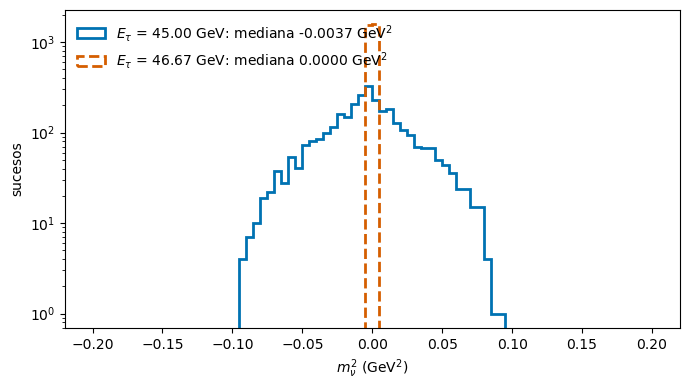

In [11]:
def neutrino(ev_vertice, E_tau):
    # m_nu^2 en los sucesos 3 pi, con p_tau en la dirección del vértice
    m2 = []
    for (ev, s), v in zip(data[data.event.isin(ev_vertice)].groupby('event'), vertices['3 pi']):
        n = v / np.linalg.norm(v)
        p_tau = np.sqrt(E_tau**2 - M_TAU**2) * n
        p_nu = p_tau - s[['px', 'py', 'pz']].to_numpy().sum(axis=0)
        E_nu = E_tau - s.E.sum()
        m2.append(E_nu**2 - p_nu @ p_nu)
    return np.array(m2)

ev3 = sorted(set(sucesos.index[sucesos.canal.isin(canales_vertice['3 pi'])]))
fig, ax = plt.subplots(figsize=(7, 4))
for E, col, ls in [(45000., AZUL, '-'), (E_TAU, BERMELLON, '--')]:
    m2 = neutrino(ev3, E)
    print('E_tau = {:.2f} GeV: m_nu^2 entre {:.4f} y {:.4f} GeV^2 (percentiles 5 y 95)'.format(E/1000, *np.percentile(m2, [5, 95])/1e6))
    ax.hist(m2 / 1e6, np.linspace(-0.2, 0.2, 81), histtype='step', lw=2, color=col, ls=ls,
            label=r'$E_\tau$ = {:.2f} GeV: mediana {:.4f} GeV$^2$'.format(E/1000, np.median(m2)/1e6))
ax.set_xlabel(r'$m_\nu^2$ (GeV$^2$)'); ax.set_ylabel('sucesos'); ax.set_yscale('log'); ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

sucesos con una solución: 66%, con dos: 34%


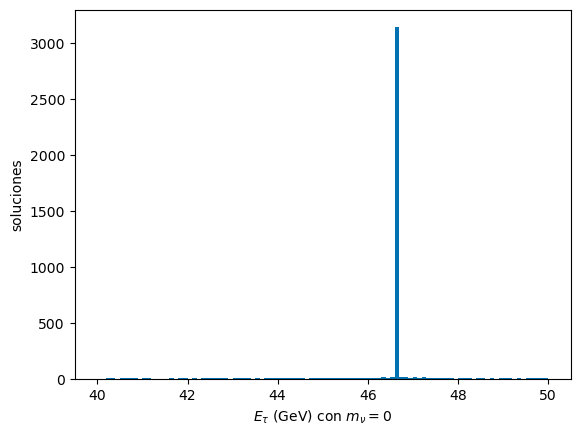

valor más repetido: 46.67 GeV


In [12]:
# 3. E_tau suceso a suceso con m_nu = 0 (puede haber dos soluciones)
E_rejilla = np.linspace(40000, 50000, 20001)
p_rejilla = np.sqrt(E_rejilla**2 - M_TAU**2)
soluciones, nraices = [], []
for (ev, s), v in zip(data[data.event.isin(ev3)].groupby('event'), vertices['3 pi']):
    n = v / np.linalg.norm(v)
    Ev, pv = s.E.sum(), s[['px', 'py', 'pz']].to_numpy().sum(axis=0)
    f = (E_rejilla - Ev)**2 - (((p_rejilla[:, None] * n) - pv)**2).sum(axis=1)
    raices = E_rejilla[np.where(np.diff(np.sign(f)))[0]]
    soluciones.extend(raices); nraices.append(len(raices))
soluciones = np.array(soluciones)
print('sucesos con una solución: {:.0%}, con dos: {:.0%}'.format(np.mean(np.array(nraices) == 1), np.mean(np.array(nraices) == 2)))
plt.hist(soluciones / 1000, np.linspace(40, 50, 101), color=AZUL)
plt.xlabel(r'$E_\tau$ (GeV) con $m_\nu = 0$'); plt.ylabel('soluciones'); plt.show()
print('valor más repetido: {:.2f} GeV'.format(pd.Series(soluciones.round(-1)).mode()[0] / 1000))

<details>
<summary><b>Solución</b></summary>

1. Con el vértice se conoce la **dirección** del $\tau$ (sale del origen), y su **energía** es la misma en todos los
   sucesos: se conoce el cuadrimomento del $\tau$, y $p_\nu = p_\tau - \sum p_i$. En los canales leptónicos hay **dos**
   neutrinos y no hay vértice: solo se conoce la suma de los dos, y ni siquiera eso sin la dirección.
2. Con $E_\tau = 45$ GeV, $m_\nu^2$ se reparte entre $-0.06$ y $+0.05$ GeV$^2$ (el 90 % de los sucesos), con valores
   negativos: no es un neutrino. Con 46.67 GeV,
   $m_\nu^2 = 0$ en todos los sucesos: la energía buena es 46.67 GeV.
3. En el 66 % de los sucesos hay una sola solución, y en el resto dos; la que se repite en todos es
   $E_\tau = 46.67$ GeV. Es la misma conclusión que con el extremo del espectro del $\pi$, por otro camino. En LEP,
   $E_\tau$ es la energía del haz, y esta reconstrucción (con los dos $\tau$ del suceso) se usa para medir la
   polarización del $\tau$.

</details>

## Resumen

* La muestra tiene 30 000 $\tau$, mitad $\tau^-$ y mitad $\tau^+$, en seis canales: $e$, $\mu$, $\pi$, $\pi\pi^0$, $\pi 2\pi^0$ y
  $3\pi$, con las fracciones del PDG renormalizadas a esos seis (el 90 % del total).

* La desintegración a dos cuerpos da un espectro **plano**; a tres cuerpos, uno blando. El extremo del espectro del
  $\pi$ es la energía del $\tau$: **46.67 GeV**.

* El vértice, con dos trayectorias, da una distancia de vuelo exponencial de media $2.29 \pm 0.02$ mm, y
  $\tau_\tau = 291 \pm 2$ fs.

* Con la energía y la dirección del $\tau$ se reconstruye el $\nu_\tau$: $m_\nu^2 = 0$ solo con la energía correcta.